In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ahsanneural/synthetic-sentiment-and-intent-data")

print("Path to dataset files:", path)

100%|██████████| 40.1k/40.1k [00:00<00:00, 35.4MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/ahsanneural/synthetic-sentiment-and-intent-data/versions/1


### 1. Download Dataset
This cell uses the `kagglehub` library to search, download, and extract the latest version of the specified dataset (`ahsanneural/synthetic-sentiment-and-intent-data`) into your local environment cache.

In [ ]:
import pandas as pd
import os

pat1 = os.path.join(path, "short_text_dataset_5000_balanced.csv")

df = pd.read_csv(pat1)
df

,ID,Text,Label,Length,Source,Timestamp
0,1,Money back please 💵,Intent: Refund,4,Chat,2024-10-28
1,2,The cat sat on the mat,Neutral,6,Chat,2024-09-19
2,3,Stop my subscription,Intent: Cancel,3,Review,2024-09-18
3,4,I love this product,Positive,4,Command,2024-01-05
4,5,Not worth the price,Negative,4,Chat,2023-09-23
...,...,...,...,...,...,...
4995,4996,I hate waiting,Negative,3,Survey,2023-09-21
4996,4997,Superb support team,Positive,3,Feedback,2024-07-27
4997,4998,Add to cart 🛒,Intent: Order,4,Chat,2023-01-27
4998,4999,bad app 👎,Negative,3,Chat,2024-11-05


### 2. Load Dataset into Pandas
Here, we use `pandas` to read the downloaded CSV file (`short_text_dataset_5000_balanced.csv`) into a DataFrame. This step loads the 5,000 synthetic rows containing raw texts, labels, text lengths, sources, and timestamps for initial viewing.

In [ ]:
df.info(

)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         5000 non-null   int64 
 1   Text       5000 non-null   object
 2   Label      5000 non-null   object
 3   Length     5000 non-null   int64 
 4   Source     5000 non-null   object
 5   Timestamp  5000 non-null   object
dtypes: int64(2), object(4)
memory usage: 234.5+ KB


### 3. Check Dataset Information
This step outputs metadata about the DataFrame (number of entries, non-null counts, and column data types) using `df.info()` to verify that everything loaded properly.

In [ ]:
print(df.isnull().sum())

ID           0
Text         0
Label        0
Length       0
Source       0
Timestamp    0
dtype: int64


### 4. Check for Missing Values
This checks for any missing (null) values in each column. The output confirms there are 0 null values across all columns.

In [ ]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


### 5. Check for Duplicates
This step checks if there are identical rows repeating in the dataset. There are no duplicate records.

In [ ]:
print(df.describe(include="all"))

                 ID             Text    Label       Length    Source  \
count   5000.000000             5000     5000  5000.000000      5000   
unique          NaN              235        8          NaN         5   
top             NaN  Refund my money  Neutral          NaN  Feedback   
freq            NaN              243      859          NaN      1032   
mean    2500.500000              NaN      NaN     3.329600       NaN   
std     1443.520003              NaN      NaN     0.878133       NaN   
min        1.000000              NaN      NaN     2.000000       NaN   
25%     1250.750000              NaN      NaN     3.000000       NaN   
50%     2500.500000              NaN      NaN     3.000000       NaN   
75%     3750.250000              NaN      NaN     4.000000       NaN   
max     5000.000000              NaN      NaN     6.000000       NaN   

         Timestamp  
count         5000  
unique         730  
top     2023-02-04  
freq            16  
mean           NaN  
std      

### 6. Summary Statistics
We run descriptive statistics here. It highlights basic patterns, such as the most common label ('Neutral'), unique values, and distribution averages for numerical columns like text 'Length'.

Label Distribution:
Label
Neutral            859
Negative           844
Positive           820
Intent: Refund     512
Intent: Cancel     506
Intent: Order      503
Intent: Support    493
Intent: Travel     463
Name: count, dtype: int64


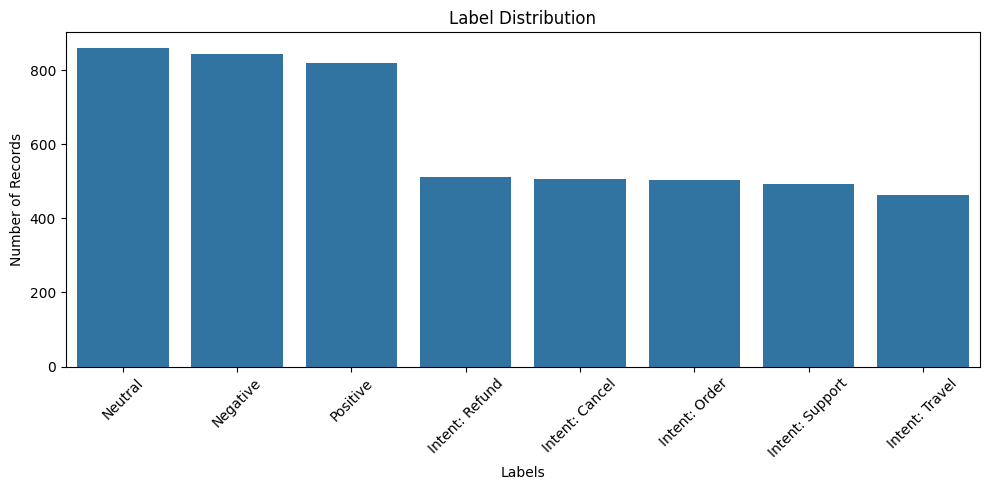

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count each label
print("Label Distribution:")
print(df["Label"].value_counts())

# Plot label distribution
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Label",
    order=df["Label"].value_counts().index
)

plt.title("Label Distribution")
plt.xlabel("Labels")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 7. Target Class Distribution Visualization
This cell uses `seaborn` and `matplotlib` to plot a frequency bar chart of our target labels. It visualizes the proportion of text samples allocated to each intent/sentiment class.

In [ ]:

import re
import pandas as pd

# Function for text cleaning
def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply text cleaning
df["Cleaned_Text"] = df["Text"].apply(clean_text)

# Display original and cleaned text
print(df[["Text", "Cleaned_Text", "Label"]].head(10).to_string(index=False))


                  Text           Cleaned_Text           Label
   Money back please 💵      money back please  Intent: Refund
The cat sat on the mat the cat sat on the mat         Neutral
  Stop my subscription   stop my subscription  Intent: Cancel
   I love this product    i love this product        Positive
   Not worth the price    not worth the price        Negative
Reserve a train ticket reserve a train ticket  Intent: Travel
    Highly recommend 👍       highly recommend        Positive
      Help me fix this       help me fix this Intent: Support
   Terrible experience    terrible experience        Negative
      luv this app!! 😍           luv this app        Positive


### 8. Text Cleaning
We define a cleaning function to convert texts to lowercase, remove URLs, discard punctuation/special characters (preserving alphanumeric characters), and remove duplicate spacing. The output shows original text alongside the resulting `Cleaned_Text`.

In [ ]:

import nltk
from nltk.corpus import stopwords

# Download stopwords
nltk.download("stopwords")

# Load English stopwords
stop_words = set(stopwords.words("english"))

# Preserve negation words
negation_words = {"no", "nor", "not"}
stop_words = stop_words - negation_words

# Function to remove stopwords
def remove_stopwords(text):
    words = text.split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(filtered_words)

# Apply stopword removal
df["Processed_Text"] = df["Cleaned_Text"].apply(remove_stopwords)

# Compare original, cleaned and processed text
print(
    df[["Text", "Cleaned_Text", "Processed_Text"]]
    .head(10)
    .to_string(index=False)
)


                  Text           Cleaned_Text       Processed_Text
   Money back please 💵      money back please    money back please
The cat sat on the mat the cat sat on the mat          cat sat mat
  Stop my subscription   stop my subscription    stop subscription
   I love this product    i love this product         love product
   Not worth the price    not worth the price      not worth price
Reserve a train ticket reserve a train ticket reserve train ticket
    Highly recommend 👍       highly recommend     highly recommend
      Help me fix this       help me fix this             help fix
   Terrible experience    terrible experience  terrible experience
      luv this app!! 😍           luv this app              luv app


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


### 9. Stopword Removal
This cell downloads and utilizes NLTK's English stopword set. It filters out common filler words while selectively retaining negation words (`no`, `nor`, `not`), which are vital for sentiment analysis.

In [ ]:

import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger_eng")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

### 10. Download NLTK Language Resources
This downloads the linguistic tokenizers, part-of-speech taggers, and morphological dictionary (WordNet) files from NLTK required for lemmatization.

In [ ]:

from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

lemmatizer = WordNetLemmatizer()

# Convert POS tag to WordNet format
def get_wordnet_pos(word):
    from nltk import pos_tag

    tag = pos_tag([word])[0][1][0].upper()

    tag_dict = {
        "J": wordnet.ADJ,
        "N": wordnet.NOUN,
        "V": wordnet.VERB,
        "R": wordnet.ADV
    }

    return tag_dict.get(tag, wordnet.NOUN)


# Tokenization and Lemmatization
def tokenize_and_lemmatize(text):
    if not isinstance(text, str):
        return ""

    tokens = word_tokenize(text)

    lemmas = [
        lemmatizer.lemmatize(word, get_wordnet_pos(word))
        for word in tokens
    ]

    return " ".join(lemmas)


# Apply on cleaned text
df["Lemmatized_Text"] = df["Cleaned_Text"].apply(
    tokenize_and_lemmatize
)

# Compare results
print(
    df[["Text", "Cleaned_Text", "Lemmatized_Text"]]
    .head(10)
    .to_string(index=False)
)


                  Text           Cleaned_Text        Lemmatized_Text
   Money back please 💵      money back please      money back please
The cat sat on the mat the cat sat on the mat the cat sat on the mat
  Stop my subscription   stop my subscription   stop my subscription
   I love this product    i love this product    i love this product
   Not worth the price    not worth the price    not worth the price
Reserve a train ticket reserve a train ticket reserve a train ticket
    Highly recommend 👍       highly recommend       highly recommend
      Help me fix this       help me fix this       help me fix this
   Terrible experience    terrible experience    terrible experience
      luv this app!! 😍           luv this app           luv this app


### 11. POS-Tag Based Lemmatization
This cell defines a pipeline that resolves words to their dictionary root form (lemmas) based on their Part of Speech (POS) tag (nouns, verbs, adjectives, etc.) to normalize grammatical variations.

In [ ]:

from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
import pandas as pd

lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words("english"))
stop_words = stop_words - {"no", "nor", "not"}

def preprocess_text(text):
    if pd.isna(text):
        return ""

    # Tokenization
    tokens = word_tokenize(str(text))

    # Stopword removal and lemmatization
    processed_words = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    return " ".join(processed_words)

# Apply preprocessing
df["Final_Text"] = df["Cleaned_Text"].apply(preprocess_text)

# Display results
print(df[["Text", "Cleaned_Text", "Final_Text"]].head(10))

# Check empty processed texts
print("\nEmpty Final Text:", df["Final_Text"].eq("").sum())


                     Text            Cleaned_Text            Final_Text
0     Money back please 💵       money back please     money back please
1  The cat sat on the mat  the cat sat on the mat           cat sat mat
2    Stop my subscription    stop my subscription     stop subscription
3     I love this product     i love this product          love product
4     Not worth the price     not worth the price       not worth price
5  Reserve a train ticket  reserve a train ticket  reserve train ticket
6      Highly recommend 👍        highly recommend      highly recommend
7        Help me fix this        help me fix this              help fix
8     Terrible experience     terrible experience   terrible experience
9        luv this app!! 😍            luv this app               luv app

Empty Final Text: 0


### 12. Final Text Preprocessing Pipeline
Combines tokenization, stopword removal, and basic lemmatization into a single efficient pipeline function to generate `Final_Text` vectors.

In [ ]:

from sklearn.preprocessing import LabelEncoder

# Create Label Encoder
le = LabelEncoder()

# Encode target column
df["Encoded_Label"] = le.fit_transform(df["Label"])

# Display label mapping
print("Label Encoding Mapping:")

for label, encoded_value in zip(
    le.classes_,
    le.transform(le.classes_)
):
    print(f"{label} = {encoded_value}")

# Display original and encoded labels
print("\nSample Encoded Data:")
print(
    df[["Label", "Encoded_Label"]]
    .head(10)
    .to_string(index=False)
)

# Check encoded class distribution
print("\nEncoded Label Distribution:")
print(df["Encoded_Label"].value_counts().sort_index())


Label Encoding Mapping:
Intent: Cancel = 0
Intent: Order = 1
Intent: Refund = 2
Intent: Support = 3
Intent: Travel = 4
Negative = 5
Neutral = 6
Positive = 7

Sample Encoded Data:
          Label  Encoded_Label
 Intent: Refund              2
        Neutral              6
 Intent: Cancel              0
       Positive              7
       Negative              5
 Intent: Travel              4
       Positive              7
Intent: Support              3
       Negative              5
       Positive              7

Encoded Label Distribution:
Encoded_Label
0    506
1    503
2    512
3    493
4    463
5    844
6    859
7    820
Name: count, dtype: int64


### 13. Label Encoding
Converts the target categorical text classes (e.g., 'Intent: Cancel', 'Positive') into numerical integers (0-7) using `scikit-learn`'s `LabelEncoder`.

In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Input text and target label
X = df["Final_Text"].fillna("")
y = df["Label"]

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Convert text into numerical features
X_tfidf = tfidf.fit_transform(X)

# Display results
print("Original Text Shape:", X.shape)
print("TF-IDF Shape:", X_tfidf.shape)




Original Text Shape: (5000,)
TF-IDF Shape: (5000, 113)


### 14. Global TF-IDF Feature Extraction
Uses a `TfidfVectorizer` to scale and convert the raw preprocessed text into numerical features based on Term Frequency-Inverse Document Frequency (TF-IDF).

In [ ]:

from sklearn.model_selection import train_test_split

# Define input and target
X = df["Final_Text"]
y = df["Encoded_Label"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Total Records:", len(df))

print("\nTraining Data:", len(X_train))
print("Testing Data:", len(X_test))

print("\nTraining Percentage:",
      round(len(X_train) / len(df) * 100, 2), "%")

print("Testing Percentage:",
      round(len(X_test) / len(df) * 100, 2), "%")

# Check class distribution
print("\nTraining Label Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Label Distribution:")
print(y_test.value_counts().sort_index())


Total Records: 5000

Training Data: 4000
Testing Data: 1000

Training Percentage: 80.0 %
Testing Percentage: 20.0 %

Training Label Distribution:
Encoded_Label
0    405
1    402
2    410
3    394
4    371
5    675
6    687
7    656
Name: count, dtype: int64

Testing Label Distribution:
Encoded_Label
0    101
1    101
2    102
3     99
4     92
5    169
6    172
7    164
Name: count, dtype: int64


### 15. Train-Test Split
Splits the dataset into 80% training data (to train the classifier) and 20% test data (to evaluate unseen records) while keeping the target class distributions balanced using stratified sampling.

In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Fit on training data and transform it
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using the same vectorizer
X_test_tfidf = tfidf.transform(X_test)

# Display shapes
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

# Display vocabulary
print("\nFirst 20 Features:")
print(tfidf.get_feature_names_out()[:20])

# Display sample TF-IDF values
print("\nFirst 5 Training Records:")
print(X_train_tfidf[:5].toarray())


Training TF-IDF Shape: (4000, 113)
Testing TF-IDF Shape: (1000, 113)

First 20 Features:
['abort' 'abortthebooking' 'add' 'addtocart' 'amazing' 'amazingexperience'
 'another' 'app' 'arrived' 'average' 'averageexperience' 'back' 'bad'
 'badapp' 'best' 'bestpurchaseever' 'book' 'bookaflighttolahore' 'booked'
 'booking']

First 5 Training Records:
[[0.70710678 0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.70710678 0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.     

### 16. Localized TF-IDF Training
Fits the TF-IDF feature vocabulary strictly on the training partition and applies that same learned transformation mapping to represent the testing subset.

XGBoost Accuracy: 96.9 %

Classification Report:
                 precision    recall  f1-score   support

 Intent: Cancel       1.00      1.00      1.00       101
  Intent: Order       1.00      0.99      1.00       101
 Intent: Refund       0.82      1.00      0.90       102
Intent: Support       1.00      0.97      0.98        99
 Intent: Travel       1.00      0.97      0.98        92
       Negative       0.97      0.87      0.92       169
        Neutral       0.98      0.99      0.99       172
       Positive       1.00      0.99      1.00       164

       accuracy                           0.97      1000
      macro avg       0.97      0.97      0.97      1000
   weighted avg       0.97      0.97      0.97      1000



<Axes: >

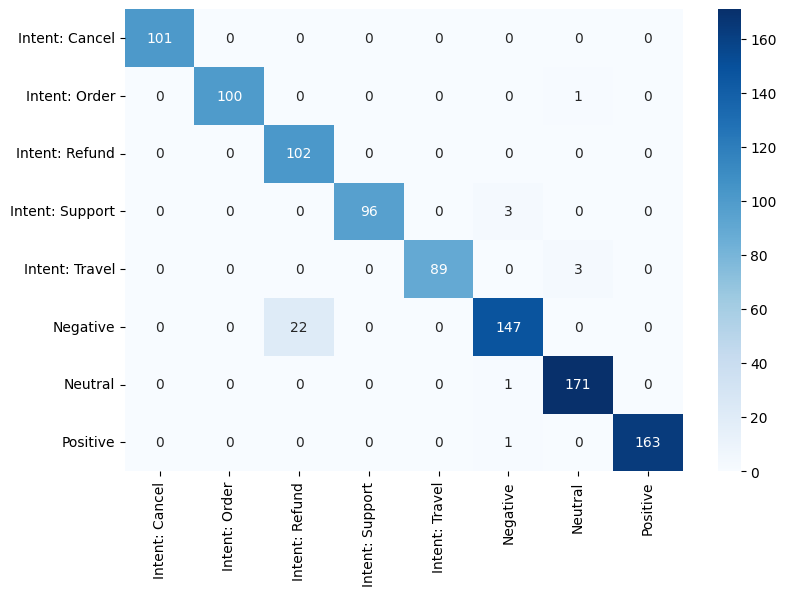

In [ ]:

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train_tfidf, y_train)

# Predictions
y_pred_xgb = xgb_model.predict(X_test_tfidf)

# Accuracy
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", round(accuracy_xgb * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_xgb,
        labels=list(range(len(le.classes_))),
        target_names=le.classes_,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=list(range(len(le.classes_)))
)

plt.figure(figsize=(9, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)




### 17. Train and Evaluate XGBoost Classifier
Trains an `XGBClassifier` ensemble model. It performs multi-class classification, outputs precision, recall, and f1-scores, and generates a confusion matrix heatmap to display classification errors.

In [ ]:

import joblib
import os

# Create folder to save files
os.makedirs("xgboost_saved_model", exist_ok=True)

# Save XGBoost model
joblib.dump(
    xgb_model,
    "xgboost_saved_model/xgb_model.pkl"
)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    "xgboost_saved_model/tfidf_vectorizer.pkl"
)

# Save Label Encoder
joblib.dump(
    le,
    "xgboost_saved_model/label_encoder.pkl"
)

print("Model, TF-IDF and Label Encoder saved successfully!")


Model, TF-IDF and Label Encoder saved successfully!


### 18. Model and Asset Serialization
Saves the trained XGBoost model file, the TF-IDF vocabulary vectorizer, and the numeric Label Encoder as serialized `.pkl` files using `joblib` so they can be reused later without retraining.

In [ ]:

import joblib

# Load trained XGBoost model
loaded_xgb_model = joblib.load(
    "xgboost_saved_model/xgb_model.pkl"
)

# Load TF-IDF vectorizer
loaded_tfidf = joblib.load(
    "xgboost_saved_model/tfidf_vectorizer.pkl"
)

# Load Label Encoder
loaded_le = joblib.load(
    "xgboost_saved_model/label_encoder.pkl"
)

print("Model loaded successfully!")


Model loaded successfully!


### 19. Load Saved Pipelines
Loads the serialized model, TF-IDF vectorizer, and label classes back into memory to establish an active inference pipeline.

In [ ]:

# New input text
new_text = [""]

# Apply the same preprocessing used during training
cleaned_text = [preprocess_text(text) for text in new_text]

# Convert text into TF-IDF features
text_tfidf = loaded_tfidf.transform(cleaned_text)

# Predict encoded label
prediction = loaded_xgb_model.predict(text_tfidf)

# Convert encoded label back to original category
predicted_label = loaded_le.inverse_transform(
    prediction.astype(int)
)

print("Input Text:", new_text[0])
print("Predicted Label:", predicted_label[0])


Input Text: I love you
Predicted Label: Positive


### 20. Live Inference Demo
This cell processes new arbitrary input string queries, applies the established tokenization and TF-IDF steps, and outputs the model's predicted sentiment/intent class label.